# 2. Why IADrift (IAGAN-style adaptation) fails for super-resolution with this drift generator

Notebook 1 showed the test result: adapting the generator's weights (IADrift) keeps lowering the measurement loss
but makes the reconstruction worse. Two explanations are possible:

| Hypothesis | Claim | Prediction |
|---|---|---|
| **Representation** | The generator can't express real photos; adaptation is too weak to fix that | adaptation fails even when the target is fully known |
| **Ill-posedness** | The adapted generator *can* express the photo, but SR ×4 leaves the frequencies above the LR limit unconstrained, and the 134M free weights fill them with whatever lowers the loss | adaptation succeeds when every frequency is measured, and SR errors concentrate above $f_{\text{LR}}$ |

| § | Experiment | Answers |
|---|---|---|
| 1 | Fit the HR image directly ($A = I$) with CSGM and with IADrift | can the adapted generator represent the photo? |
| 2 | Radial SNR: where in frequency the SR errors are | is the extra error above $f_{\text{LR}}$? |
| 3 | Adapt the weights only ($\varepsilon$ frozen) | which part drives the failure? |
| 4 | In-range SR: targets drawn from the generator itself | what controls content: $\varepsilon$ or the noise labels $z$? |
| 5 | Tile seams in the generator's own samples | are the 16-pixel artifacts caused by the inversion? |

**Evidence tier: development.** All experiments use **4 development images** (never test images): 8117 streetcar,
3939 bonnet, 403 crane, 347 spoonbill, correct class label. With $n = 4$ we report means and every per-image value,
not significance tests. §1 uses the HR image as the optimization target on purpose: it is a diagnostic, not a method.

**About the code cells.** They show each method in compact form. The code that produced the numbers is the runner named in the table below (`scripts/dev/`, built on the library
`iadrift/`); each has `--dry-run` and a `--smoke` check that reruns part of a saved run bit-exactly. The raw
development notebooks the runners were ported from are in `notebooks/dev_archive/` (outputs cleared).

| Result | Produced by |
|---|---|
| CSGM and IADrift on the development images (SR rows) | `scripts/dev/run_csgm_dev.py`, `scripts/dev/run_iadrift_dev.py` (the IADrift learning-rate grid) |
| §1 CSGM-HR (A = I) and §4 in-range SR | `scripts/dev/run_representation_dev.py` |
| §1 IADrift-HR (A = I) | `scripts/dev/run_hr_fit_dev.py` |
| §3 θ-only adaptation | `scripts/dev/run_theta_only_dev.py` |
| §4 in-range targets x\*, §5 random samples (forward passes) | `scripts/dev/run_generator_samples_dev.py` |
| All metrics in this notebook | `scripts/analysis/export_dev_results.py` → `results/dev_*` |

## Setup

In [1]:
import json
import os
from pathlib import Path

os.environ.setdefault("JAX_PLATFORMS", "cpu")

import jax
import jax.numpy as jnp
import optax
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = REPO / "results"
dev = json.loads((RESULTS / "dev_metrics.json").read_text())
traces = json.loads((RESULTS / "dev_traces.json").read_text())
_ex = np.load(RESULTS / "dev_examples.npz")
EX = lambda key: _ex[key].astype(np.float32)

DEV = [8117, 3939, 403, 347]
NAME = {i: dev["images"][str(i)]["class"] for i in DEV}
BANDS = ["low", "mid", "high", "very high"]
F_LR = 0.125
show = lambda x: (np.clip(x, -1, 1) + 1) / 2


def val(method, key, i, src="images"):
    m = dev[src][str(i)][method]
    return m["band_snr_db"][key] if key in BANDS else m[key]


def mean(method, key, src="images"):
    return float(np.mean([val(method, key, i, src) for i in DEV]))


def table(caption, rows, cols, src="images"):
    """rows: [(display name, method key)]; cols: [(header, metric key, format)]. Mean over the 4 images."""
    lines = ["| Method | " + " | ".join(h for h, _, _ in cols) + " |", "|---|" + "---:|" * len(cols)]
    for name, method in rows:
        lines.append(f"| {name} | " + " | ".join(f"{mean(method, k, src):{f}}" for _, k, f in cols) + " |")
    display(Markdown(f"**{caption}**\n\n" + "\n".join(lines)))


def per_image_table(caption, rows, src="images"):
    lines = ["| Method | " + " | ".join(f"{i} ({NAME[i]})" for i in DEV) + " |", "|---|" + "---:|" * len(DEV)]
    for name, method in rows:
        lines.append(f"| {name} | " + " | ".join(f"{val(method, 'psnr', i, src):.2f} / {val(method, 'lpips', i, src):.3f}"
                                              for i in DEV) + " |")
    display(Markdown(f"**{caption}** (PSNR dB / LPIPS)\n\n" + "\n".join(lines)))


CROP = 80


def detail_crop(ref):
    g = np.abs(np.diff(ref.mean(-1), axis=0))[:, :-1] + np.abs(np.diff(ref.mean(-1), axis=1))[:-1, :]
    pos = [(r, c) for r in range(0, 256 - CROP, 16) for c in range(0, 256 - CROP, 16)]
    return max(pos, key=lambda p: g[p[0]:p[0] + CROP, p[1]:p[1] + CROP].sum())


def side_by_side(ref, ref_title, panels, title):
    """panels: [(name, image, metrics or None)]. Top: full images; bottom: an 80x80 detail crop (yellow box)."""
    r, c = detail_crop(ref)
    fig, axes = plt.subplots(2, len(panels) + 1, figsize=(3.2 * (len(panels) + 1), 6.8))
    axes[0, 0].imshow(show(ref))
    axes[0, 0].add_patch(plt.Rectangle((c, r), CROP, CROP, fill=False, color="yellow", lw=1.5))
    axes[0, 0].set_title(ref_title, fontsize=9)
    axes[1, 0].imshow(show(ref[r:r + CROP, c:c + CROP]), interpolation="nearest")
    for k, (name, x, m) in enumerate(panels, start=1):
        axes[0, k].imshow(show(x))
        axes[0, k].set_title(name + ("" if m is None else f"\n{m['psnr']:.2f} dB / LPIPS {m['lpips']:.3f}"), fontsize=9)
        axes[1, k].imshow(show(x[r:r + CROP, c:c + CROP]), interpolation="nearest")
    for ax in axes.flat:
        ax.axis("off")
    fig.suptitle(title, fontsize=11)
    plt.tight_layout()
    plt.show()


print("development images:", ", ".join(f"{i} ({NAME[i]})" for i in DEV))

development images: 8117 (streetcar), 3939 (bonnet), 403 (crane), 347 (spoonbill)


## 1. Representation or ill-posedness? Fit the HR image directly

The representation experiment of the IAGAN paper, run with **our two methods**: remove the degradation ($A = I$)
and fit the known HR image $x^\star$.

$$
\textbf{CSGM-HR:}\quad \hat\varepsilon = \arg\min_\varepsilon \|x^\star - G_{\theta_0}(\varepsilon; z, c)\|_2^2
\qquad\qquad
\textbf{IADrift-HR:}\quad (\hat\theta, \hat\varepsilon) = \arg\min_{\theta, \varepsilon} \|x^\star - G_{\theta}(\varepsilon; z, c)\|_2^2
$$

- CSGM-HR: the CSGM recipe of notebook 1 (Adam lr 0.02, 5,000 steps, best of 2 restarts by HR loss).
- IADrift-HR: **exactly the IADrift code of notebook 1**, only with $A = I$ and target $x^\star$. It starts from the CSGM-HR solution and adapts all weights $\theta$ and $\varepsilon$ with the **same optimizer
  and learning rates as IADrift** ($\theta$: $10^{-5}$ or $10^{-6}$; $\varepsilon$: $10^{-3}$), 2,000 steps.
- The only difference from SR is the operator: with $A = I$ every frequency is constrained; with $A = A_{\text{sr4}}$
  everything above $f_{\text{LR}}$ is free.

The three losses differ only in the operator and in which variables are free:

In [2]:
def data_loss(generate, theta, eps, target, A):
    """||target - A G_theta(eps)||^2. SR: A = A_sr4, target = y. HR fit: A = identity, target = x*."""
    return jnp.sum((A(generate(theta, eps)) - target) ** 2)


identity = lambda x: x
# CSGM / CSGM-HR:   gradient w.r.t. eps only           (theta = theta_0 frozen)
# IADrift / IADrift-HR: gradient w.r.t. (theta, eps)     (Adam: theta lr 1e-5, eps lr 1e-3)
# Code of the runs: iadrift/adaptation.py (joint step), scripts/dev/run_hr_fit_dev.py (HR fit), scripts/dev/run_representation_dev.py (CSGM-HR)

In [3]:
ROWS_HR = [("bicubic (SR ×4)", "bicubic"), ("CSGM (SR ×4)", "CSGM"), ("IADrift, 1,000 steps (SR ×4)", "IADrift"),
           ("**CSGM-HR** (A = I, ε only)", "CSGM-HR"), ("**IADrift-HR**, θ lr 1e-6 (A = I)", "IADrift-HR, lr 1e-06"),
           ("**IADrift-HR**, θ lr 1e-5 (A = I)", "IADrift-HR, lr 1e-05")]
table("Table 6. Fitting the HR image directly vs SR ×4 (4 development images, mean). HR fits use HR as the target.",
      ROWS_HR, [("PSNR (dB) ↑", "psnr", ".2f"), ("LPIPS ↓", "lpips", ".3f"), ("SNR high", "high", "+.1f"),
                ("SNR very high", "very high", "+.1f")])
per_image_table("Per image", ROWS_HR)

**Table 6. Fitting the HR image directly vs SR ×4 (4 development images, mean). HR fits use HR as the target.**

| Method | PSNR (dB) ↑ | LPIPS ↓ | SNR high | SNR very high |
|---|---:|---:|---:|---:|
| bicubic (SR ×4) | 24.94 | 0.484 | +0.5 | +0.0 |
| CSGM (SR ×4) | 21.06 | 0.406 | -2.6 | -6.0 |
| IADrift, 1,000 steps (SR ×4) | 18.30 | 0.470 | -4.2 | -10.6 |
| **CSGM-HR** (A = I, ε only) | 24.44 | 0.332 | +1.8 | -0.8 |
| **IADrift-HR**, θ lr 1e-6 (A = I) | 28.29 | 0.189 | +6.1 | +1.2 |
| **IADrift-HR**, θ lr 1e-5 (A = I) | 40.09 | 0.030 | +19.5 | +14.4 |

**Per image** (PSNR dB / LPIPS)

| Method | 8117 (streetcar) | 3939 (bonnet) | 403 (crane) | 347 (spoonbill) |
|---|---:|---:|---:|---:|
| bicubic (SR ×4) | 24.63 / 0.458 | 25.75 / 0.442 | 25.30 / 0.633 | 24.09 / 0.406 |
| CSGM (SR ×4) | 19.61 / 0.395 | 22.27 / 0.388 | 20.63 / 0.573 | 21.71 / 0.267 |
| IADrift, 1,000 steps (SR ×4) | 16.49 / 0.519 | 20.12 / 0.390 | 16.01 / 0.697 | 20.58 / 0.275 |
| **CSGM-HR** (A = I, ε only) | 23.55 / 0.266 | 25.47 / 0.253 | 23.62 / 0.580 | 25.14 / 0.230 |
| **IADrift-HR**, θ lr 1e-6 (A = I) | 27.87 / 0.117 | 29.95 / 0.103 | 25.91 / 0.395 | 29.42 / 0.142 |
| **IADrift-HR**, θ lr 1e-5 (A = I) | 39.38 / 0.007 | 42.32 / 0.039 | 38.47 / 0.023 | 40.19 / 0.050 |

**Figure 6** follows IADrift-HR over its 2,000 steps (mean over the 4 images; step 0 = the CSGM-HR solution).

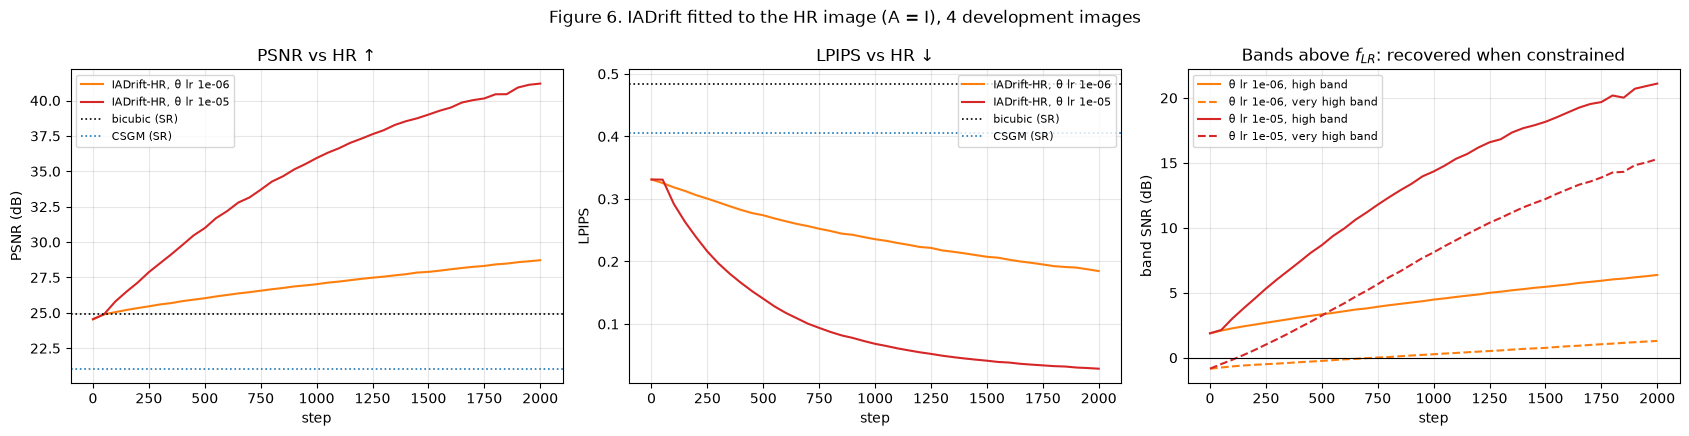

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for lt, color in (("1e-06", "C1"), ("1e-05", "C3")):
    ts = [traces["hr_fit"][f"{i}|{lt}"] for i in DEV]
    steps = ts[0]["step"]
    axes[0].plot(steps, np.mean([t["psnr"] for t in ts], axis=0), color=color, label=f"IADrift-HR, θ lr {lt}")
    axes[1].plot(steps, np.mean([t["lpips"] for t in ts], axis=0), color=color, label=f"IADrift-HR, θ lr {lt}")
    for b, ls in (("high", "-"), ("very high", "--")):
        axes[2].plot(steps, np.mean([t[b] for t in ts], axis=0), color=color, ls=ls, label=f"θ lr {lt}, {b} band")
for ax, key in ((axes[0], "psnr"), (axes[1], "lpips")):
    for name, method, color in (("bicubic (SR)", "bicubic", "k"), ("CSGM (SR)", "CSGM", "C0")):
        ax.axhline(mean(method, key), color=color, ls=":", lw=1.2, label=name)
axes[0].set(xlabel="step", ylabel="PSNR (dB)", title="PSNR vs HR ↑")
axes[1].set(xlabel="step", ylabel="LPIPS", title="LPIPS vs HR ↓")
axes[2].axhline(0, color="k", lw=0.8)
axes[2].set(xlabel="step", ylabel="band SNR (dB)", title="Bands above $f_{LR}$: recovered when constrained")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.suptitle("Figure 6. IADrift fitted to the HR image (A = I), 4 development images", fontsize=12)
plt.tight_layout()
plt.show()

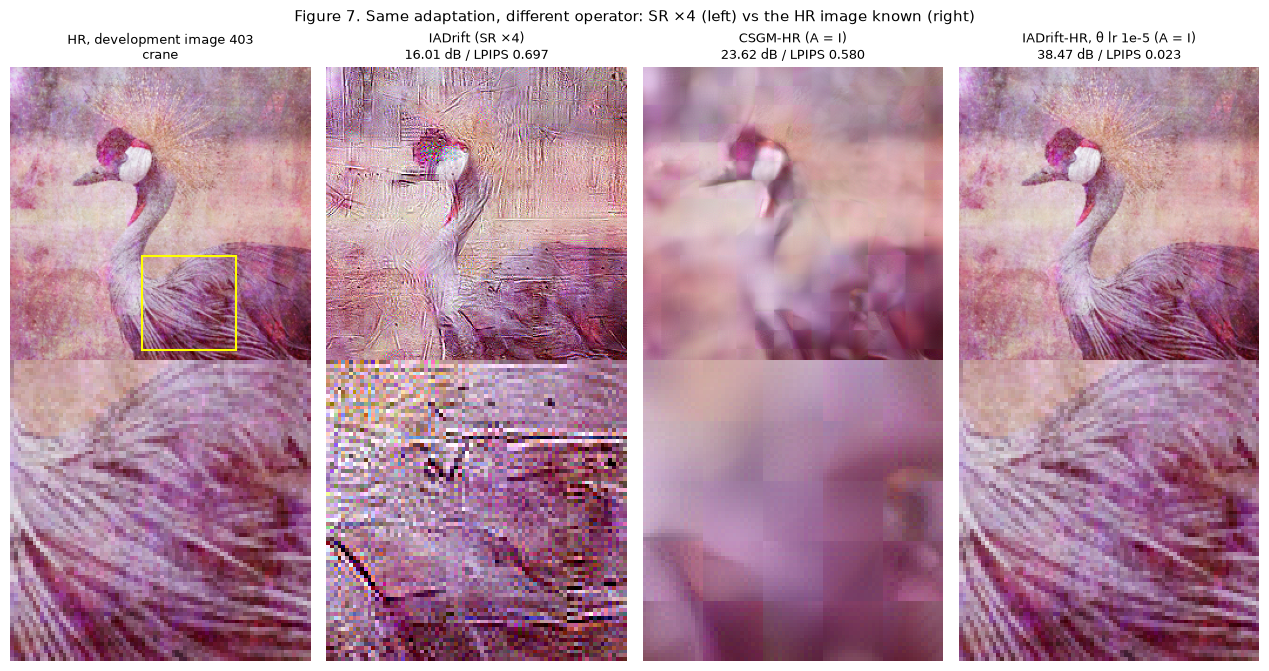

In [5]:
i = 403
m = dev["images"][str(i)]
side_by_side(EX(f"{i}|HR"), f"HR, development image {i}\n{NAME[i]}",
             [("IADrift (SR ×4)", EX(f"{i}|IADrift"), m["IADrift"]), ("CSGM-HR (A = I)", EX(f"{i}|CSGM-HR"), m["CSGM-HR"]),
              ("IADrift-HR, θ lr 1e-5 (A = I)", EX(f"{i}|IADrift-HR, lr 1e-05"), m["IADrift-HR, lr 1e-05"])],
             "Figure 7. Same adaptation, different operator: SR ×4 (left) vs the HR image known (right)")

**Reading.** With the image fully known, the frozen generator reaches only about 24.4 dB (below bicubic SR):
the drift prior alone has a large representation error. The **same adaptation** that fails in SR closes this gap
almost completely (about 40 dB, LPIPS 0.03, every image above 38 dB), including the bands above $f_{\text{LR}}$ and
without tile seams. So the adapted generator *can* represent these photos. What differs in SR is only the operator:
the result supports **ill-posedness**, not representation, as the cause of the SR failure.

## 2. Where the SR errors are: radial SNR

Let $\hat X(k)$ and $X^\star(k)$ be the 2D Fourier transforms of the reconstruction and the HR image (Hann window,
summed over colour channels). For a ring of radial frequencies $B = \{k : f \le |k| < f + \Delta f\}$:

$$
\mathrm{SNR}(f) = 10 \log_{10} \frac{\sum_{k \in B} |X^\star(k)|^2}{\sum_{k \in B} |\hat X(k) - X^\star(k)|^2} \quad \text{dB}.
$$

$0$ dB means the error in that ring is as large as the true content, i.e. no better than leaving it empty (which is
what bicubic does above $f_{\text{LR}}$). Below $f_{\text{LR}} = 0.125$ the measurement constrains the content; above
it nothing does.

In [6]:
def radial_snr_db(x, ref, num_bins=48):
    """(bin centres, SNR in dB per ring) from 0 to 0.5 cycles/pixel (iadrift/metrics.py)."""
    window = np.outer(np.hanning(256), np.hanning(256))[..., None]
    power = lambda a: np.sum(np.abs(np.fft.fft2(np.asarray(a, np.float64) * window, axes=(0, 1))) ** 2, axis=-1)
    fy, fx = np.fft.fftfreq(256)[:, None], np.fft.fftfreq(256)[None, :]
    radius = np.sqrt(fx ** 2 + fy ** 2)
    signal, error = power(ref), power(np.asarray(x, np.float64) - ref)
    edges = np.linspace(0, 0.5, num_bins + 1)
    snr = [10 * np.log10(signal[(radius >= lo) & (radius < hi)].sum() / error[(radius >= lo) & (radius < hi)].sum())
           for lo, hi in zip(edges[:-1], edges[1:])]
    return (edges[:-1] + edges[1:]) / 2, np.array(snr)


i = 403
f, s = radial_snr_db(EX(f"{i}|CSGM + BP"), EX(f"{i}|HR"))
d = np.abs(s - np.array(dev["images"][str(i)]["CSGM + BP"]["radial_snr"]))
print(f"check vs the exported curve: max difference {d[f >= 0.0625].max():.3f} dB at f >= 0.0625 "
      "(below, float16 rounding of the stored example images caps the ~50 dB SNR of the lowest rings)")

check vs the exported curve: max difference 0.001 dB at f >= 0.0625 (below, float16 rounding of the stored example images caps the ~50 dB SNR of the lowest rings)


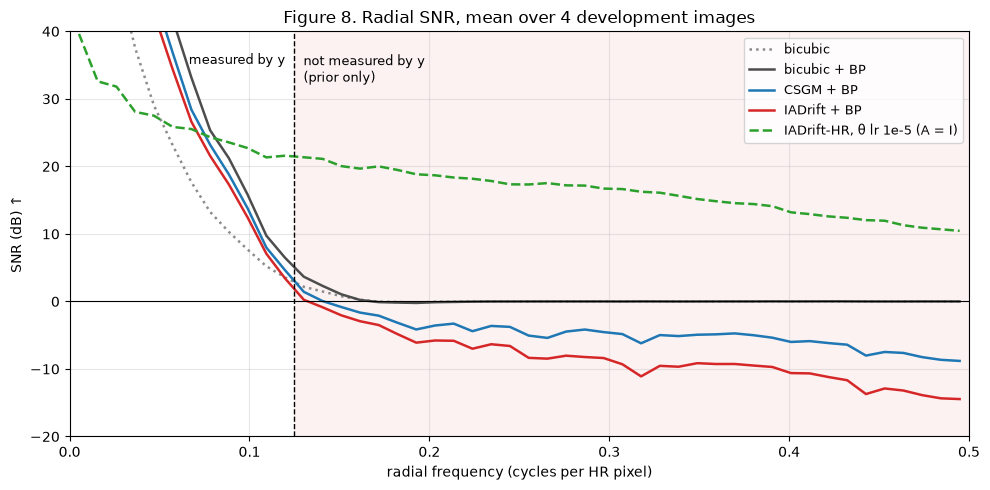

**Table 7. Band SNR (dB), 4 development images**

| Method | low | mid | high | very high | PSNR (dB) |
|---|---:|---:|---:|---:|---:|
| bicubic | +37.5 | +9.1 | +0.5 | +0.0 | 24.94 |
| bicubic + BP | +56.8 | +14.4 | +0.7 | +0.0 | 25.43 |
| CSGM + BP | +52.0 | +12.6 | -2.3 | -6.0 | 21.86 |
| IADrift + BP | +49.4 | +11.4 | -4.2 | -10.6 | 18.31 |
| IADrift-HR, θ lr 1e-5 (A = I) | +33.5 | +23.5 | +19.5 | +14.4 | 40.09 |

In [7]:
freqs = np.array(dev["radial_freqs"])
CURVES = [("bicubic", "bicubic", "0.55", ":"), ("bicubic + BP", "bicubic + BP", "0.3", "-"), ("CSGM + BP", "CSGM + BP", "C0", "-"),
          ("IADrift + BP", "IADrift + BP", "C3", "-"), ("IADrift-HR, θ lr 1e-5 (A = I)", "IADrift-HR, lr 1e-05", "C2", "--")]
fig, ax = plt.subplots(figsize=(10, 5))
for name, method, color, ls in CURVES:
    ax.plot(freqs, np.mean([dev["images"][str(i)][method]["radial_snr"] for i in DEV], axis=0), color=color, ls=ls, lw=1.8, label=name)
ax.set_ylim(-20, 40)  # the lowest rings reach 50-120 dB after BP; the interesting part is around 0 dB
ax.axvline(F_LR, color="k", ls="--", lw=1)
ax.axvspan(F_LR, 0.5, color="C3", alpha=0.06)
ax.axhline(0, color="k", lw=0.8)
ax.text(F_LR + 0.005, ax.get_ylim()[1] * 0.92, "not measured by y\n(prior only)", fontsize=9, va="top")
ax.text(F_LR - 0.005, ax.get_ylim()[1] * 0.92, "measured by y", fontsize=9, va="top", ha="right")
ax.set(xlim=(0, 0.5), xlabel="radial frequency (cycles per HR pixel)", ylabel="SNR (dB) ↑",
       title="Figure 8. Radial SNR, mean over 4 development images")
ax.grid(alpha=0.3)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

table("Table 7. Band SNR (dB), 4 development images", [(n, m) for n, m, _, _ in CURVES],
      [(f"{b}", b, "+.1f") for b in BANDS] + [("PSNR (dB)", "psnr", ".2f")])

**Reading.** Below $f_{\text{LR}}$, back-projected reconstructions are all close (the measurement pins them down).
Above $f_{\text{LR}}$, bicubic stays at 0 dB (it adds nothing), while CSGM + BP and, more so, IADrift + BP go **below
0 dB**: the content they invent there is worse than nothing. IADrift-HR, whose loss constrains every frequency, is
far above 0 dB everywhere. The same generator, adapted the same way, is only accurate where the loss sees the image.

## 3. The weights drive the failure: θ-only adaptation

Freeze the CSGM input and adapt **only** the weights:

$$
\hat\theta = \arg\min_\theta \big\|y - A\, G_\theta(\hat\varepsilon_{\text{CSGM}}; z, c)\big\|_2^2 ,
\qquad \text{Adam on all 134M weights, 2,000 steps, } \theta \text{ lr} \in \{10^{-6}, 10^{-5}\}.
$$

If this reproduces IADrift, the weights (not the input) cause the degradation.

In [8]:
def make_theta_only_step(loss_fn, optimizer):
    """IADrift with eps frozen: the gradient is taken w.r.t. theta only (argnums=0)."""
    def step(theta, state, eps, y, label, z):
        loss, g = jax.value_and_grad(loss_fn, argnums=0)(theta, eps, y, label, z)
        updates, state = optimizer.update(g, state, theta)
        return optax.apply_updates(theta, updates), state, loss
    return step  # = iadrift.adaptation.Adaptation.make_theta_step; the runs: scripts/dev/run_theta_only_dev.py

**Table 8. θ-only adaptation from the CSGM solution (4 development images, mean)**

| Method | PSNR (dB) ↑ | LPIPS ↓ | LR loss | SNR low | SNR mid | SNR high | SNR very high |
|---|---:|---:|---:|---:|---:|---:|---:|
| bicubic | 24.94 | 0.484 | 9.5 | +37.5 | +9.1 | +0.5 | +0.0 |
| bicubic + BP | 25.43 | 0.429 | 0.0 | +56.8 | +14.4 | +0.7 | +0.0 |
| CSGM (start, step 0) | 21.06 | 0.406 | 50.5 | +20.7 | +5.3 | -2.6 | -6.0 |
| θ-only, lr 1e-6, 2,000 steps | 18.78 | 0.454 | 7.8 | +27.9 | +9.7 | -4.2 | -9.9 |
| θ-only, lr 1e-5, 2,000 steps | 18.18 | 0.481 | 1.1 | +34.0 | +11.3 | -4.2 | -10.8 |
| IADrift (θ and ε), 1,000 steps | 18.30 | 0.470 | 2.0 | +32.8 | +11.0 | -4.2 | -10.6 |

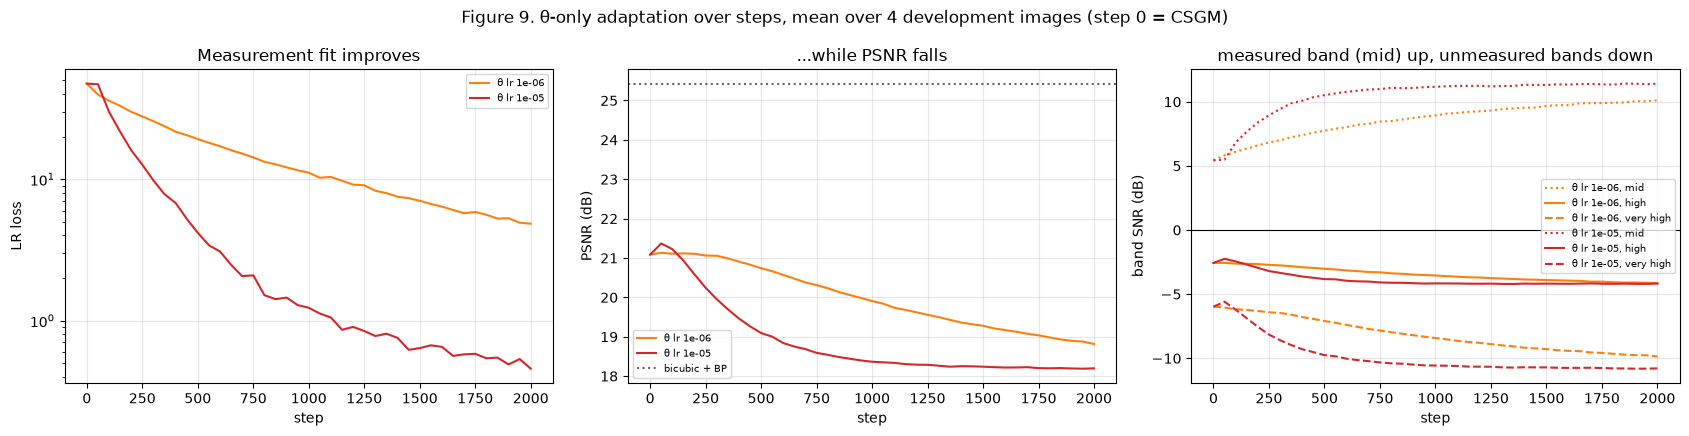

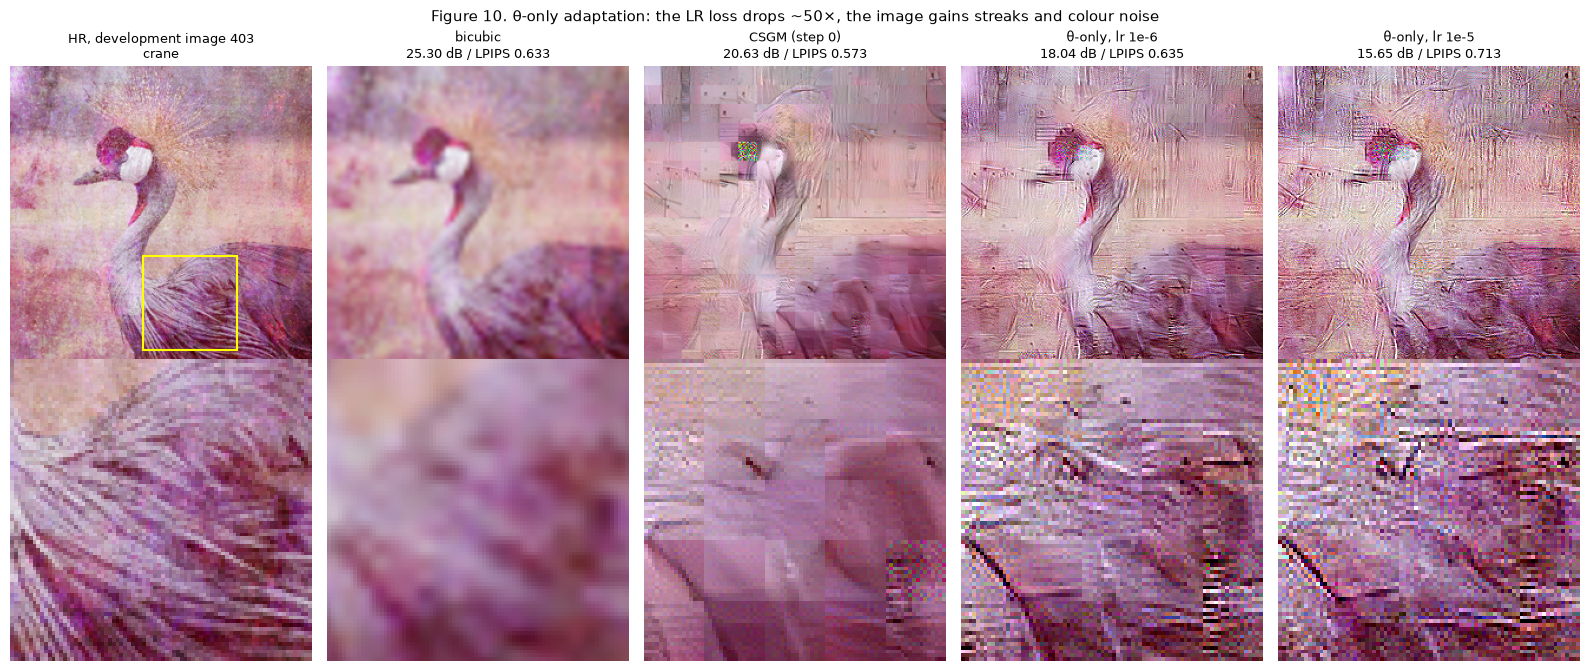

In [9]:
ROWS_T = [("bicubic", "bicubic"), ("bicubic + BP", "bicubic + BP"), ("CSGM (start, step 0)", "CSGM"),
          ("θ-only, lr 1e-6, 2,000 steps", "theta-only, lr 1e-06"), ("θ-only, lr 1e-5, 2,000 steps", "theta-only, lr 1e-05"),
          ("IADrift (θ and ε), 1,000 steps", "IADrift")]
table("Table 8. θ-only adaptation from the CSGM solution (4 development images, mean)", ROWS_T,
      [("PSNR (dB) ↑", "psnr", ".2f"), ("LPIPS ↓", "lpips", ".3f"), ("LR loss", "lr_loss", ".1f")] +
      [(f"SNR {b}", b, "+.1f") for b in BANDS])

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for lt, color in (("1e-06", "C1"), ("1e-05", "C3")):
    ts = [traces["theta_only"][f"{i}|{lt}"] for i in DEV]
    st = ts[0]["step"]
    axes[0].plot(st, np.mean([t["lr_loss"] for t in ts], axis=0), color=color, label=f"θ lr {lt}")
    axes[1].plot(st, np.mean([t["psnr"] for t in ts], axis=0), color=color, label=f"θ lr {lt}")
    for b, ls in (("mid", ":"), ("high", "-"), ("very high", "--")):
        axes[2].plot(st, np.mean([t[b] for t in ts], axis=0), color=color, ls=ls, label=f"θ lr {lt}, {b}")
axes[0].set(yscale="log", xlabel="step", ylabel="LR loss", title="Measurement fit improves")
axes[1].axhline(mean("bicubic + BP", "psnr"), color="0.4", ls=":", label="bicubic + BP")
axes[1].set(xlabel="step", ylabel="PSNR (dB)", title="...while PSNR falls")
axes[2].axhline(0, color="k", lw=0.8)
axes[2].set(xlabel="step", ylabel="band SNR (dB)", title="measured band (mid) up, unmeasured bands down")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
fig.suptitle("Figure 9. θ-only adaptation over steps, mean over 4 development images (step 0 = CSGM)", fontsize=12)
plt.tight_layout()
plt.show()

i = 403
m = dev["images"][str(i)]
side_by_side(EX(f"{i}|HR"), f"HR, development image {i}\n{NAME[i]}",
             [("bicubic", EX(f"{i}|bicubic"), m["bicubic"]), ("CSGM (step 0)", EX(f"{i}|CSGM"), m["CSGM"]),
              ("θ-only, lr 1e-6", EX(f"{i}|theta-only, lr 1e-06"), m["theta-only, lr 1e-06"]),
              ("θ-only, lr 1e-5", EX(f"{i}|theta-only, lr 1e-05"), m["theta-only, lr 1e-05"])],
             "Figure 10. θ-only adaptation: the LR loss drops ~50×, the image gains streaks and colour noise")

**Reading.** Adapting the weights alone reproduces IADrift (about 18.2 dB vs 18.3 dB at θ lr $10^{-5}$): the
input $\varepsilon$ contributes almost nothing. The measured mid band improves, the unmeasured bands get worse,
and PSNR falls while the loss being optimized drops by a factor of about 50.

## 4. What controls content: in-range SR

To remove representation error entirely, draw the target from the generator itself and super-resolve it:

$$
x^\star = G_{\theta_0}(\varepsilon^\star; z^\star, c), \quad \varepsilon^\star \sim \mathcal N(0, I),\ z^\star \text{ random}; \qquad
y^\star = A x^\star; \qquad \text{CSGM from } y^\star \text{ with } z = z^\star \text{ (known) or } z \text{ random (as in practice)}.
$$

A perfect inversion exists ($\varepsilon = \varepsilon^\star$, LR loss 0). Scores are against $x^\star$. The 32 noise
labels $z$ are discrete, so CSGM cannot optimize them: it keeps the random draw.

**Table 9. In-range SR ×4: targets from the generator, scored against x* (4 targets, mean)**

| Method | PSNR (dB) ↑ | LPIPS ↓ | LR loss |
|---|---:|---:|---:|
| bicubic | 22.62 | 0.455 | 13.9 |
| bicubic + BP | 23.03 | 0.402 | 0.0 |
| CSGM, z known (= z*) | 25.93 | 0.116 | 19.3 |
| CSGM, z random (the real setting) | 21.89 | 0.331 | 40.4 |

ε is not recovered even when the image is: ‖ε − ε*‖ / ‖ε*‖ = 1.97, 1.68, 1.74, 1.69 (z known).

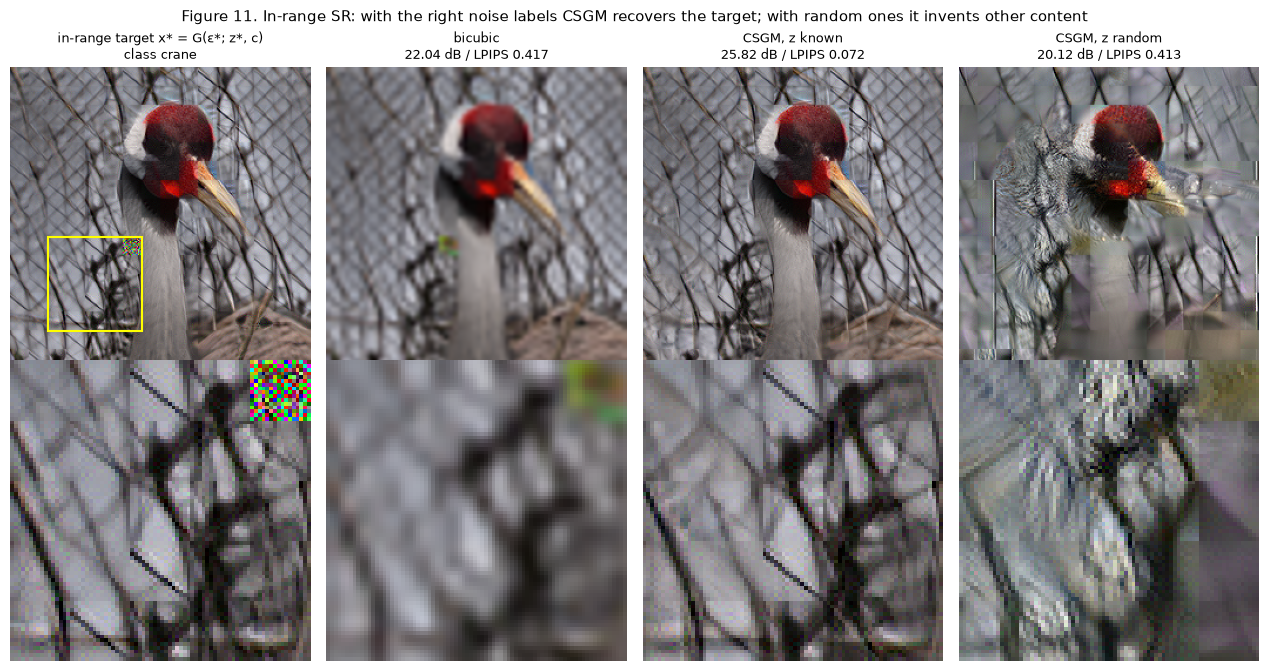

In [10]:
ROWS_R3 = [("bicubic", "bicubic"), ("bicubic + BP", "bicubic + BP"),
           ("CSGM, z known (= z*)", "CSGM, noise labels known"), ("CSGM, z random (the real setting)", "CSGM, noise labels random")]
table("Table 9. In-range SR ×4: targets from the generator, scored against x* (4 targets, mean)", ROWS_R3,
      [("PSNR (dB) ↑", "psnr", ".2f"), ("LPIPS ↓", "lpips", ".3f"), ("LR loss", "lr_loss", ".1f")], src="r3")
display(Markdown("ε is not recovered even when the image is: ‖ε − ε*‖ / ‖ε*‖ = " + ", ".join(
    f"{dev['r3'][str(i)]['CSGM, noise labels known']['eps_rel_error']:.2f}" for i in DEV) + " (z known)."))

i = 403
m = dev["r3"][str(i)]
side_by_side(EX(f"r3|{i}|x*"), f"in-range target x* = G(ε*; z*, c)\nclass {NAME[i]}",
             [("bicubic", EX(f"r3|{i}|bicubic"), m["bicubic"]),
              ("CSGM, z known", EX(f"r3|{i}|CSGM, noise labels known"), m["CSGM, noise labels known"]),
              ("CSGM, z random", EX(f"r3|{i}|CSGM, noise labels random"), m["CSGM, noise labels random"])],
             "Figure 11. In-range SR: with the right noise labels CSGM recovers the target; with random ones it invents other content")

**Reading.** When the target is in the generator's range, CSGM with the right noise labels beats bicubic by
about 3 dB and is perceptually close to exact (LPIPS 0.12). With random noise labels it loses 4 dB and fills the
image with the wrong texture. The discrete code $z$, which no gradient method can optimize, decides the content; and
many different $\varepsilon$ produce nearly the same image.

## 5. The 16-pixel tile seams come from the generator

The generator outputs each $16\times16$ patch from its own token, so a seam at the patch borders shows up in the
spectrum as energy on the lines $f = k/16$ cycles/pixel. With $P(k_x, k_y)$ the power spectrum (Hann window, mean
removed), the **patch-grid score** is

$$
S = \frac{\text{mean } P \text{ on the lines } k/16,\ k = 1..7 \text{ (both axes)}}{\text{mean } P \text{ on the neighbouring lines } k/16 \pm 2/256}
\qquad (S \approx 1: \text{no grid}).
$$

**Table 10. Patch-grid score** (≈ 1 = no 16-pixel grid)

| Images | n | score |
|---|---:|---:|
| HR (truth) | 4 | 0.97 |
| bicubic | 4 | 0.94 |
| **random samples of the generator** (CFG 1.0, no inversion) | 8 | 1.54 |
| CSGM | 4 | 1.67 |
| IADrift (SR) | 4 | 1.74 |
| θ-only, lr 1e-5 (SR) | 4 | 1.74 |
| CSGM-HR (A = I) | 4 | 1.06 |
| IADrift-HR, θ lr 1e-5 (A = I) | 4 | 0.97 |

check: 1.004 vs exported 1.004


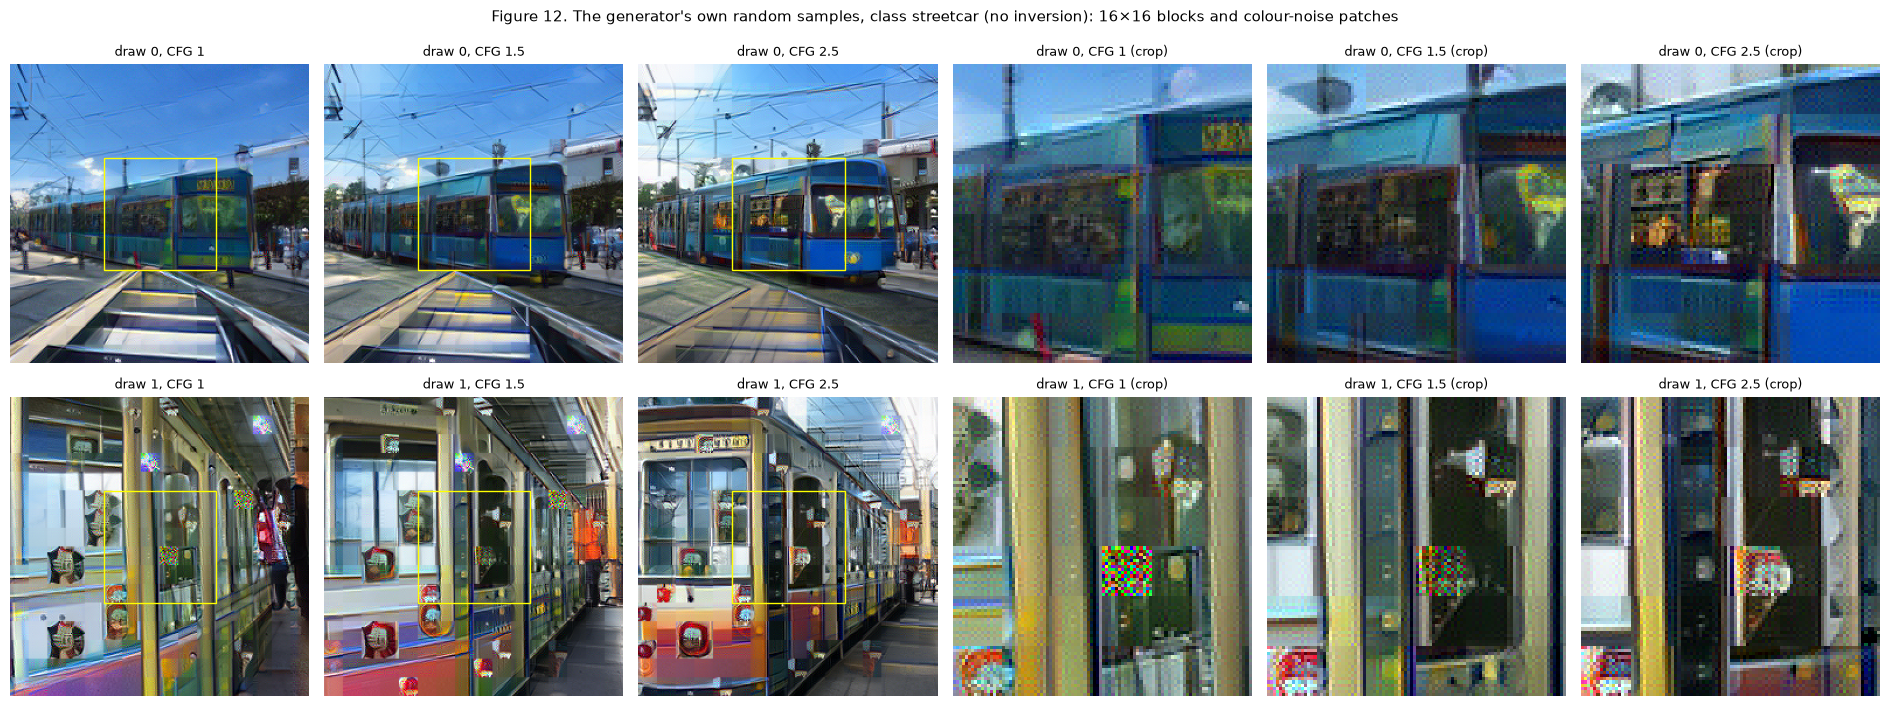

In [11]:
def grid_score(x):
    x = np.asarray(x, np.float64)
    window = np.outer(np.hanning(256), np.hanning(256))[..., None]
    p = np.sum(np.abs(np.fft.fft2((x - x.mean(axis=(0, 1))) * window, axes=(0, 1))) ** 2, axis=-1)
    on = np.mean([p[:, 16 * k].mean() + p[16 * k, :].mean() for k in range(1, 8)])
    off = np.mean([p[:, 16 * k + s].mean() + p[16 * k + s, :].mean() for k in range(1, 8) for s in (-2, 2)])
    return float(on / off)


samples_cfg1 = [s for i in DEV for s in dev["samples_grid_score"][str(i)]]
rows = [("HR (truth)", np.mean([dev["images"][str(i)]["HR"]["grid_score"] for i in DEV]), 4),
        ("bicubic", mean("bicubic", "grid_score"), 4),
        ("**random samples of the generator** (CFG 1.0, no inversion)", np.mean(samples_cfg1), len(samples_cfg1)),
        ("CSGM", mean("CSGM", "grid_score"), 4), ("IADrift (SR)", mean("IADrift", "grid_score"), 4),
        ("θ-only, lr 1e-5 (SR)", mean("theta-only, lr 1e-05", "grid_score"), 4),
        ("CSGM-HR (A = I)", mean("CSGM-HR", "grid_score"), 4), ("IADrift-HR, θ lr 1e-5 (A = I)", mean("IADrift-HR, lr 1e-05", "grid_score"), 4)]
display(Markdown("**Table 10. Patch-grid score** (≈ 1 = no 16-pixel grid)\n\n| Images | n | score |\n|---|---:|---:|\n"
                 + "\n".join(f"| {n} | {k} | {s:.2f} |" for n, s, k in rows)))
print("check:", round(grid_score(EX("403|HR")), 3), "vs exported", round(dev["images"]["403"]["HR"]["grid_score"], 3))

i, c0, cs = 8117, 80, 96
fig, axes = plt.subplots(2, 6, figsize=(19, 7.4))
for d in (0, 1):
    for k, cfg in enumerate(("1", "1.5", "2.5")):
        x = EX(f"sample|{i}|{d}|{cfg}")
        axes[d, k].imshow(show(x))
        axes[d, k].add_patch(plt.Rectangle((c0, c0), cs, cs, fill=False, color="yellow", lw=1))
        axes[d, k].set_title(f"draw {d}, CFG {cfg}", fontsize=9)
        axes[d, 3 + k].imshow(show(x[c0:c0 + cs, c0:c0 + cs]), interpolation="nearest")
        axes[d, 3 + k].set_title(f"draw {d}, CFG {cfg} (crop)", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
fig.suptitle(f"Figure 12. The generator's own random samples, class {NAME[i]} (no inversion): 16×16 blocks and colour-noise patches", fontsize=11)
plt.tight_layout()
plt.show()

**Reading.** The grid is already in the generator's own samples (score about 1.5, vs about 1.0 for HR and bicubic),
at every guidance scale: it is a property of `pixel_B_sota`, not of our inversion. Inversion raises it only
modestly. Adapting the weights to the full HR image removes it completely (score equal to HR's), so it is not
unavoidable either; in SR, though, removing seams (IADrift @1000 in notebook 1) comes with noise elsewhere.

## 6. Summary

1. **Not representation:** with the HR image known, the same IADrift procedure reaches about 40 dB / LPIPS 0.03,
   while the frozen generator stops at 24.4 dB (Table 6, Figures 6–7). The adapted drift generator can represent
   these photos.
2. **Ill-posedness:** in SR, the errors added by the prior sit above the LR limit, where the measurement says nothing;
   adaptation makes them larger (Figure 8, Table 7).
3. **The weights do it:** adapting $\theta$ alone reproduces IADrift; the measurement loss falls about 50× while PSNR
   and the unmeasured bands fall (Table 8, Figures 9–10).
4. **The discrete noise labels $z$ decide content:** even for in-range targets, random $z$ costs 4 dB (Table 9,
   Figure 11).
5. **Tile seams are the generator's own** (Table 10, Figure 12).

So what should help is not more freedom for the generator but **removing wrong content above $f_{\text{LR}}$**:
back-projection (notebook 1), and averaging several reconstructions so that their unconstrained, disagreeing details
cancel (notebook 3).